<!-- 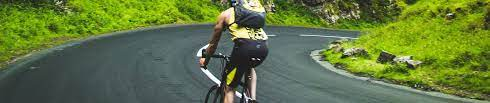


## Project Summary. 
Trip duration is the most fundamental measure in all modes of transportation. Hence, it is crucial to predict the trip-time precisely for the advancement of Intelligent Transport Systems (ITS) and traveller information systems. In order to predict the trip duration, data mining techniques are employed in this project to predict the trip duration of rental bikes in Seoul Bike sharing system. The prediction is carried out with the combination of Seoul Bike data and weather data.
## Please use the Seoul Bike dataset. 

- What are the factors that influence the number of bikes rented? 
- Explore the data for outliers and missing values.
- Plot the correlation between the variables and state your comments
- Please build a linear regression model to predict rented bike count by choosing appropriate independentvariables.
- Comment on Model performance by using approapriate diagnostics and measures.

Good Luck! -->

## Project Summary

Trip duration is the most fundamental measure in all modes of transportation. Hence, it is crucial to predict the trip-time precisely for the advancement of Intelligent Transport Systems (ITS) and traveller information systems. In order to predict the trip duration, data mining techniques are employed in this project to predict the trip duration of rental bikes in Seoul Bike sharing system. The prediction is carried out with the combination of Seoul Bike data and weather data.


**Please use the Seoul Bike dataset.**


What are the factors that influence the number of bikes rented?

Explore the data for outliers and missing values.

Plot the correlation between the variables and state your comments

Please build a linear regression model to predict rented bike count by choosing appropriate independent variables.

Coment on Model performance by using approapriate diagnostics and measures.

In [60]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
sns.set(style='white', color_codes=True)


In [61]:
data = pd.read_csv('/content/SeoulBikeData.csv')

In [62]:
data.head()

,Date,Rented Bike Count,Hour,Temperature(C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [63]:
print("Diamension of the dataset : ", data.shape)

Diamension of the dataset :  (8760, 14)


# What are the factors that influence the number of bikes rented? 

In [64]:
factors = data.columns.values
print("Factors : ",factors)

Factors :  ['Date' 'Rented Bike Count' 'Hour' 'Temperature(C)' 'Humidity(%)'
 'Wind speed (m/s)' 'Visibility (10m)' 'Dew point temperature(C)'
 'Solar Radiation (MJ/m2)' 'Rainfall(mm)' 'Snowfall (cm)' 'Seasons'
 'Holiday' 'Functioning Day']


In [65]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Date                      8760 non-null   object 
 1   Rented Bike Count         8760 non-null   int64  
 2   Hour                      8760 non-null   int64  
 3   Temperature(C)            8760 non-null   float64
 4   Humidity(%)               8760 non-null   int64  
 5   Wind speed (m/s)          8760 non-null   float64
 6   Visibility (10m)          8760 non-null   int64  
 7   Dew point temperature(C)  8760 non-null   float64
 8   Solar Radiation (MJ/m2)   8760 non-null   float64
 9   Rainfall(mm)              8760 non-null   float64
 10  Snowfall (cm)             8760 non-null   float64
 11  Seasons                   8760 non-null   object 
 12  Holiday                   8760 non-null   object 
 13  Functioning Day           8760 non-null   object 
dtypes: float

In [66]:
data.describe()

,Rented Bike Count,Hour,Temperature(C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm)
count,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000
mean,704.602055,11.500000,12.882922,58.226256,1.724909,1436.825799,4.073813,0.569111,0.148687,0.075068
std,644.997468,6.922582,11.944825,20.362413,1.036300,608.298712,13.060369,0.868746,1.128193,0.436746
min,0.000000,0.000000,-17.800000,0.000000,0.000000,27.000000,-30.600000,0.000000,0.000000,0.000000
25%,191.000000,5.750000,3.500000,42.000000,0.900000,940.000000,-4.700000,0.000000,0.000000,0.000000
50%,504.500000,11.500000,13.700000,57.000000,1.500000,1698.000000,5.100000,0.010000,0.000000,0.000000
75%,1065.250000,17.250000,22.500000,74.000000,2.300000,2000.000000,14.800000,0.930000,0.000000,0.000000
max,3556.000000,23.000000,39.400000,98.000000,7.400000,2000.000000,27.200000,3.520000,35.000000,8.800000


# Explore the data for outliers and missing values.

In [67]:
#Missing values count
data.isnull().sum()

Date                        0
Rented Bike Count           0
Hour                        0
Temperature(C)              0
Humidity(%)                 0
Wind speed (m/s)            0
Visibility (10m)            0
Dew point temperature(C)    0
Solar Radiation (MJ/m2)     0
Rainfall(mm)                0
Snowfall (cm)               0
Seasons                     0
Holiday                     0
Functioning Day             0
dtype: int64

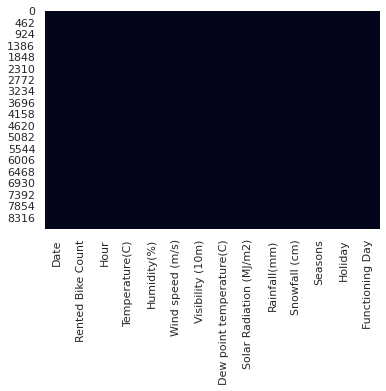

In [68]:
#Missing values map, missing values can be
    #found as white dots along each column,
    #here there are no missing values
sns.heatmap(data.isnull(), cbar=False)
plt.show()

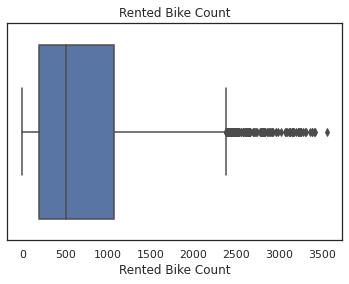

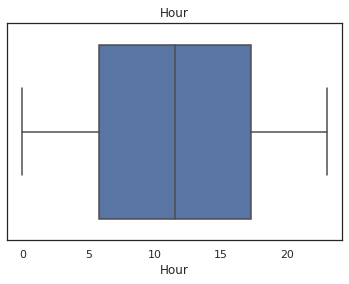

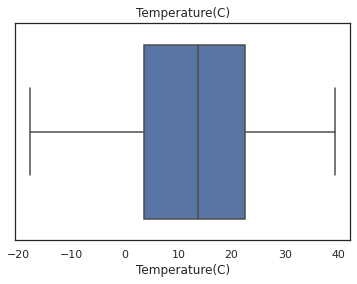

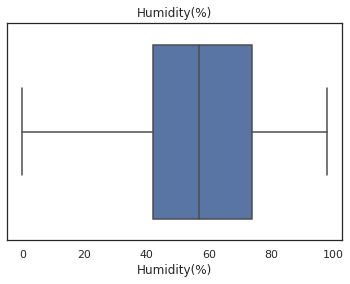

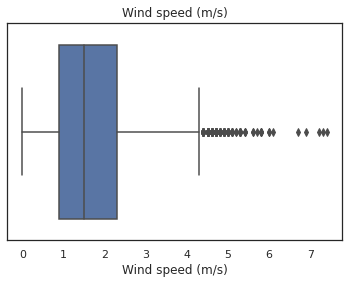

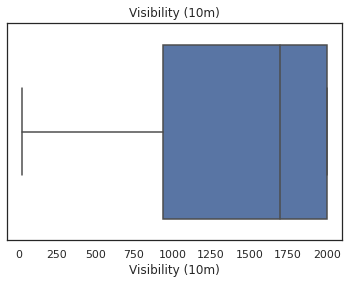

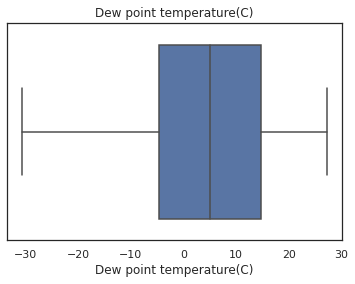

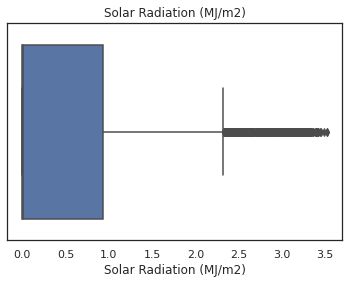

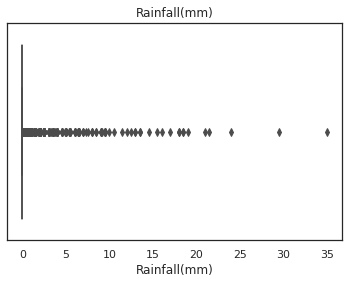

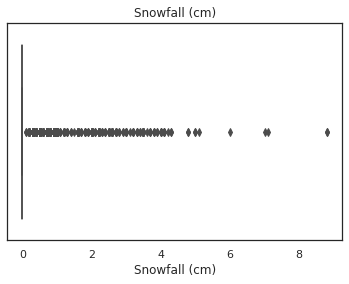

In [69]:
# Outliers can be observed using the boxplot
column_names = data.select_dtypes(include=["int64","float64","uint8"]).columns.values
for col in column_names:
    sns.boxplot(data[col])
    plt.title(col)
    plt.show()

In [70]:
#Columns with outliers
outlier_cols = ['Rented Bike Count','Wind speed (m/s)','Solar Radiation (MJ/m2)']

In [71]:
# Dealing with outliers
for col in outlier_cols:
    
    Q1 = np.percentile(data[col], 25, interpolation = 'midpoint')  
    Q2 = np.percentile(data[col], 50, interpolation = 'midpoint')  
    Q3 = np.percentile(data[col], 75, interpolation = 'midpoint')     
    IQR = Q3 - Q1 
    low_lim = Q1 - 1.5 * IQR 
    up_lim = Q3 + 1.5 * IQR
    print('low limit {}:'.format(col), low_lim) 
    print('upper limit {}:'.format(col), up_lim)
    
    data = data[data[col]< up_lim]
    data=data[data[col]> low_lim]

low limit Rented Bike Count: -1120.75
upper limit Rented Bike Count: 2377.25
low limit Wind speed (m/s): -1.1999999999999997
upper limit Wind speed (m/s): 4.3999999999999995
low limit Solar Radiation (MJ/m2): -1.35
upper limit Solar Radiation (MJ/m2): 2.25


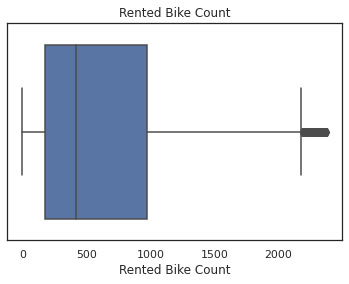

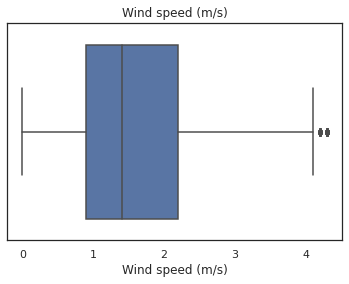

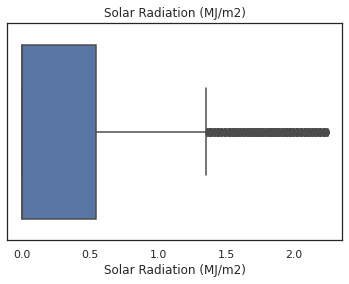

In [72]:
for col in outlier_cols:
    sns.boxplot(data[col])
    plt.title(col)
    plt.show()

# Plot the correlation between the variables and state your comments

In [73]:
data_corr = data.corr()
data_corr

,Rented Bike Count,Hour,Temperature(C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm)
Rented Bike Count,1.000000,0.400517,0.533168,-0.162957,0.106349,0.188051,0.381486,0.248899,-0.125173,-0.140926
Hour,0.400517,1.000000,0.098512,-0.226957,0.279841,0.086136,-0.011491,0.144502,0.012919,-0.013805
Temperature(C),0.533168,0.098512,1.000000,0.258581,-0.081031,0.004416,0.926904,0.246831,0.066321,-0.215724
Humidity(%),-0.162957,-0.226957,0.258581,1.000000,-0.300416,-0.545389,0.591577,-0.389027,0.237412,0.098863
Wind speed (m/s),0.106349,0.279841,-0.081031,-0.300416,1.000000,0.162613,-0.190484,0.287703,-0.014117,0.007440
Visibility (10m),0.188051,0.086136,0.004416,-0.545389,0.162613,1.000000,-0.192794,0.114031,-0.166442,-0.119595
Dew point temperature(C),0.381486,-0.011491,0.926904,0.591577,-0.190484,-0.192794,1.000000,0.040846,0.134135,-0.149055
Solar Radiation (MJ/m2),0.248899,0.144502,0.246831,-0.389027,0.287703,0.114031,0.040846,1.000000,-0.066099,-0.050075
Rainfall(mm),-0.125173,0.012919,0.066321,0.237412,-0.014117,-0.166442,0.134135,-0.066099,1.000000,0.006405
Snowfall (cm),-0.140926,-0.013805,-0.215724,0.098863,0.007440,-0.119595,-0.149055,-0.050075,0.006405,1.000000


In [74]:
# Values in the range of 1 to -1,value 1 most correlated,
            #negative values inversely correlated
    
data_corr = data_corr['Rented Bike Count'][:-1].sort_values(ascending=False)
print(data_corr)

Rented Bike Count           1.000000
Temperature(C)              0.533168
Hour                        0.400517
Dew point temperature(C)    0.381486
Solar Radiation (MJ/m2)     0.248899
Visibility (10m)            0.188051
Wind speed (m/s)            0.106349
Rainfall(mm)               -0.125173
Humidity(%)                -0.162957
Name: Rented Bike Count, dtype: float64


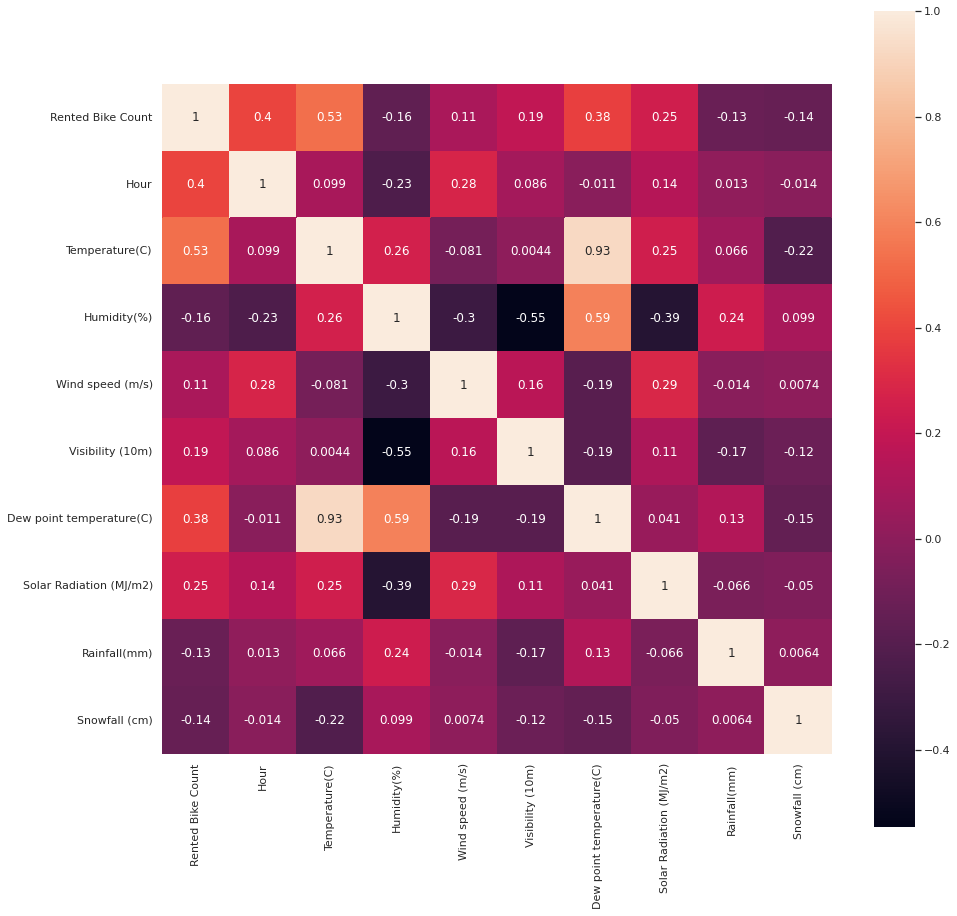

In [75]:
#Correlation map
corr = data.corr()
plt.figure(figsize=(15,15))
sns.heatmap(corr, annot=True,square=True) 
plt.show()

In [76]:
# Drop negatively correlated columns
from datetime import datetime
data.Date=pd.to_datetime(data.Date )
data.info()
data['Month']=pd.DatetimeIndex(data['Date']).month
data['Year']=pd.DatetimeIndex(data['Date']).year
data['tday']=pd.DatetimeIndex(data['Date']).day
data
data.drop(['Humidity(%)','Rainfall(mm)'],axis=1,inplace=True)

<class 'pandas.core.frame.DataFrame'>
Int64Index: 7752 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Date                      7752 non-null   datetime64[ns]
 1   Rented Bike Count         7752 non-null   int64         
 2   Hour                      7752 non-null   int64         
 3   Temperature(C)            7752 non-null   float64       
 4   Humidity(%)               7752 non-null   int64         
 5   Wind speed (m/s)          7752 non-null   float64       
 6   Visibility (10m)          7752 non-null   int64         
 7   Dew point temperature(C)  7752 non-null   float64       
 8   Solar Radiation (MJ/m2)   7752 non-null   float64       
 9   Rainfall(mm)              7752 non-null   float64       
 10  Snowfall (cm)             7752 non-null   float64       
 11  Seasons                   7752 non-null   object        
 12  Holiday             

In [77]:

data.drop('Date',axis=1,inplace=True)
data

,Rented Bike Count,Hour,Temperature(C),Wind speed (m/s),Visibility (10m),Dew point temperature(C),Solar Radiation (MJ/m2),Snowfall (cm),Seasons,Holiday,Functioning Day,Month,Year,tday
0,254,0,-5.2,2.2,2000,-17.6,0.0,0.0,Winter,No Holiday,Yes,1,2017,12
1,204,1,-5.5,0.8,2000,-17.6,0.0,0.0,Winter,No Holiday,Yes,1,2017,12
2,173,2,-6.0,1.0,2000,-17.7,0.0,0.0,Winter,No Holiday,Yes,1,2017,12
3,107,3,-6.2,0.9,2000,-17.6,0.0,0.0,Winter,No Holiday,Yes,1,2017,12
4,78,4,-6.0,2.3,2000,-18.6,0.0,0.0,Winter,No Holiday,Yes,1,2017,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,1003,19,4.2,2.6,1894,-10.3,0.0,0.0,Autumn,No Holiday,Yes,11,2018,30
8756,764,20,3.4,2.3,2000,-9.9,0.0,0.0,Autumn,No Holiday,Yes,11,2018,30
8757,694,21,2.6,0.3,1968,-9.9,0.0,0.0,Autumn,No Holiday,Yes,11,2018,30
8758,712,22,2.1,1.0,1859,-9.8,0.0,0.0,Autumn,No Holiday,Yes,11,2018,30


In [78]:
catcol=data.select_dtypes(include='object')

In [79]:
print("Categorical Values:", catcol.head())

Categorical Values:   Seasons     Holiday Functioning Day
0  Winter  No Holiday             Yes
1  Winter  No Holiday             Yes
2  Winter  No Holiday             Yes
3  Winter  No Holiday             Yes
4  Winter  No Holiday             Yes


In [80]:
Bikes_df=data
for cols in catcol:
  dummies =pd.get_dummies(data[cols],drop_first=True)
  Bikes_df = pd.concat([Bikes_df,dummies],axis='columns')

In [81]:
Bikes_df.head()

,Rented Bike Count,Hour,Temperature(C),Wind speed (m/s),Visibility (10m),Dew point temperature(C),Solar Radiation (MJ/m2),Snowfall (cm),Seasons,Holiday,Functioning Day,Month,Year,tday,Spring,Summer,Winter,No Holiday,Yes
0,254,0,-5.2,2.2,2000,-17.6,0.0,0.0,Winter,No Holiday,Yes,1,2017,12,0,0,1,1,1
1,204,1,-5.5,0.8,2000,-17.6,0.0,0.0,Winter,No Holiday,Yes,1,2017,12,0,0,1,1,1
2,173,2,-6.0,1.0,2000,-17.7,0.0,0.0,Winter,No Holiday,Yes,1,2017,12,0,0,1,1,1
3,107,3,-6.2,0.9,2000,-17.6,0.0,0.0,Winter,No Holiday,Yes,1,2017,12,0,0,1,1,1
4,78,4,-6.0,2.3,2000,-18.6,0.0,0.0,Winter,No Holiday,Yes,1,2017,12,0,0,1,1,1


In [82]:
Bikes_df.drop({'Seasons','Holiday','Functioning Day'},axis=1,inplace=True)

In [83]:
from sklearn.preprocessing import StandardScaler
# Initialise the Scaler
scaler = StandardScaler()
  
# To scale data
scaler.fit(Bikes_df)
#from sklearn.preprocessing import normalize
#normalize(df1)

StandardScaler(copy=True, with_mean=True, with_std=True)

# Please build a linear regression model to predict rented bike count by choosing appropriate independentvariables.


In [84]:
from sklearn.model_selection import train_test_split
train, val = train_test_split(Bikes_df, test_size=0.25)

In [85]:
#considering only the highly correlated features for training and validation
train_x = train.drop(['Rented Bike Count'], axis = 1)
train_y = train['Rented Bike Count']             # output of the training data

val_x = val.drop(['Rented Bike Count'], axis = 1)
val_y = val['Rented Bike Count']

In [86]:
print('Dimension of train_x dataframe:',train_x.shape)
print('Dimension of train_y dataframe:',train_y.shape)
print('Dimension of val_x dataframe:',val_x.shape)
print('Dimension of val_y dataframe:',val_y.shape)

Dimension of train_x dataframe: (5814, 15)
Dimension of train_y dataframe: (5814,)
Dimension of val_x dataframe: (1938, 15)
Dimension of val_y dataframe: (1938,)


In [87]:
from sklearn.linear_model import LinearRegression
ln_reg = LinearRegression()
ln_reg.fit(train_x, train_y)

LinearRegression(copy_X=True, fit_intercept=True, n_jobs=None, normalize=False)

# Comment on Model performance by using approapriate diagnostics and measures.

In [88]:
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
df_pred = ln_reg.predict(val_x)
print('Mean Absolute Error of linear regression:',mean_absolute_error(df_pred, val_y))
print('Mean Square Error of linear regression:', mean_squared_error(df_pred, val_y))
print('R_Squared Score of linear regression:', r2_score(df_pred, val_y))
print('Accuracy:',ln_reg.score(val_x,val_y))

Mean Absolute Error of linear regression: 311.49669480921847
Mean Square Error of linear regression: 165033.9008962768
R_Squared Score of linear regression: 0.17092647365142255
Accuracy: 0.5339684988850294


### Observations

- Factors selected to be valid for training are :-
    - Rented Bike Count
    - Hour
    - Temperature(C)
    - Wind speed (m/s)
    - Visibility (10m)
    - Dew point temperature(C)
    - Solar Radiation (MJ/m2)
    - Snowfall (cm)
    - Month
    - Year
    - Day
    
- a)Columns with outliers :- 
    - Rented Bike Count
    - Wind speed (m/s)
    - Solar Radiation (MJ/m2)'
  
  b)Columns with missing values :- None

- Correlation with dependant variable :-
    - Rented Bike Count           1.000000
    - Temperature(C)              0.533168
    - Hour                        0.400517
    - Dew point temperature(C)    0.381486
    - Solar Radiation (MJ/m2)     0.248899
    - Visibility (10m)            0.188051
    - Wind speed (m/s)            0.106349
    - Rainfall(mm)               -0.125173
    - Humidity(%)                -0.162957
    
    Dropped due to negative correlation : Rainfall(mm), Humidity(%)
    
- Model Diagnostics :-
    - Mean Absolute Error of linear regression: 311.49669480921847
    - Mean Square Error of linear regression: 165033.9008962768
    - R_Squared Score of linear regression: 0.17092647365142255
    - Accuracy: 0.5339684988850294
- Comments : Accuracy visibly lower due to lack of usable data points


<hr style="height:30px;border-width:0;color:black;background-color:gray">
